# Credit risk on the German Credit data: EDA and training

This notebook explores the data and then **calls the same functions as `src/train.py`**, so the
notebook and the script cannot drift apart. The committed model in `models/` is produced by the script
(`python src/train.py`); here the identical procedure runs with `save=False` and we plot the results.

Dataset: OpenML `credit-g` v1 = UCI Statlog German Credit Data (CC BY 4.0), 1,000 loan applications,
30% labelled `bad`. See `data/README.md` for the column dictionary.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the repo root importable whether the notebook runs from notebooks/ or from the root.
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data import NUMERIC_FEATURES, POSITIVE_LABEL, PROTECTED_ATTRIBUTES, TARGET, load_data
from src.train import run_training

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Two colours, used consistently: blue = good (repaid), orange = bad (defaulted).
GOOD, BAD, MUTED, GRID = "#2a78d6", "#eb6834", "#898781", "#e1e0d9"


def tidy(ax, title=None):
    """Minimal chart chrome: no top/right spines, light grid, muted ticks."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title, loc="left", fontsize=11, fontweight="bold")


df = load_data()
print(df.shape)
df.head()

(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


## 1. Class balance

Only 30% of applicants are `bad`. A model that always says "good" is 70% accurate and completely useless,
which is why this project reports ROC-AUC, PR-AUC, recall of the bad class and a cost view instead of
accuracy, and why both candidate models use `class_weight="balanced"`.

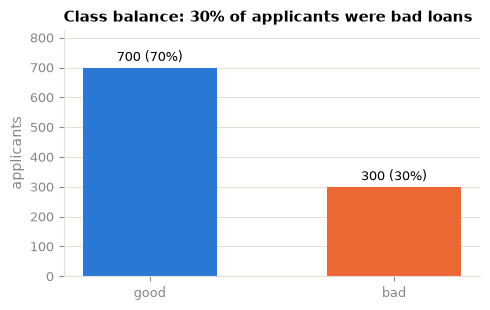

In [2]:
counts = df[TARGET].value_counts()
share = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(counts.index, counts.values, color=[GOOD if c == "good" else BAD for c in counts.index], width=0.55)
for bar, n, s in zip(bars, counts.values, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 12, f"{n} ({s:.0%})", ha="center", va="bottom", fontsize=9)
tidy(ax, "Class balance: 30% of applicants were bad loans")
ax.set_ylabel("applicants", color=MUTED)
ax.set_ylim(0, counts.max() * 1.18)
fig.tight_layout()
fig.savefig(FIG_DIR / "class_balance.png", dpi=150)
plt.show()

## 2. Numeric features by outcome

Bad loans tend to be larger and longer. The density histograms overlap a lot, though: no single
numeric column separates the classes, which is why the model needs all 17 inputs.

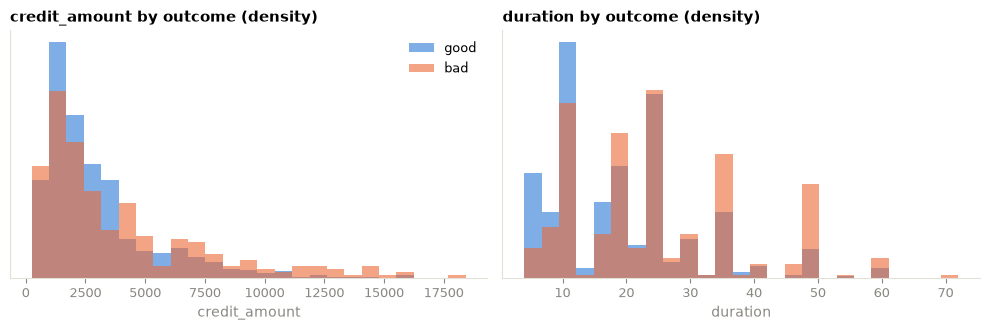

,duration,credit_amount,installment_commitment,residence_since,existing_credits,num_dependents
class,,,,,,
bad,24.0,2574.5,4.0,3.0,1.0,1.0
good,18.0,2244.0,3.0,3.0,1.0,1.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col in zip(axes, ["credit_amount", "duration"]):
    bins = np.histogram_bin_edges(df[col], bins=25)
    for label, color in [("good", GOOD), ("bad", BAD)]:
        ax.hist(df.loc[df[TARGET] == label, col], bins=bins, color=color, alpha=0.6, label=label, density=True)
    tidy(ax, f"{col} by outcome (density)")
    ax.set_xlabel(col, color=MUTED)
    ax.set_yticks([])
    ax.yaxis.grid(False)
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "numeric_by_class.png", dpi=150)
plt.show()

df.groupby(TARGET)[NUMERIC_FEATURES].median()

## 3. Share of bad loans by category

`checking_status` is the strongest single signal in this dataset. The famous counter-intuitive pattern:
applicants with **no checking account** default far less often than those whose account is overdrawn (`<0`).

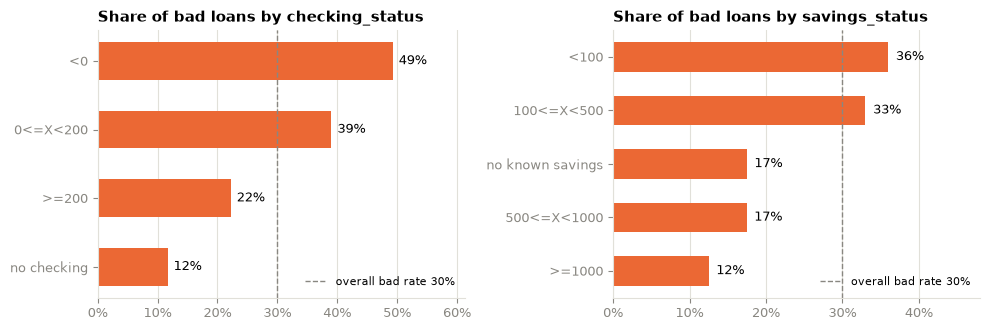

In [4]:
tmp = df.assign(is_bad=(df[TARGET] == POSITIVE_LABEL).astype(int))
overall = tmp["is_bad"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col in zip(axes, ["checking_status", "savings_status"]):
    rates = tmp.groupby(col)["is_bad"].mean().sort_values()
    bars = ax.barh(rates.index, rates.values, color=BAD, height=0.55)
    for bar, v in zip(bars, rates.values):
        ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.0%}", va="center", fontsize=9)
    ax.axvline(overall, color=MUTED, linestyle="--", linewidth=1, label=f"overall bad rate {overall:.0%}")
    tidy(ax, f"Share of bad loans by {col}")
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.yaxis.grid(False)
    ax.set_xlim(0, rates.max() + 0.12)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "default_rate_by_category.png", dpi=150)
plt.show()

## 4. Protected attributes: predictive, but not used

The data also records `age`, `personal_status` (which encodes sex) and `foreign_worker`. They carry signal,
as the tables below show, but deciding credit on sex, nationality or age is discriminatory and illegal in
many jurisdictions. `src/data.py` lists them under `PROTECTED_ATTRIBUTES`, they are **not** model inputs,
and `src/train.py` measures what leaving them out costs (section 5).

In [5]:
tmp["age_group"] = pd.cut(df["age"], bins=[18, 25, 35, 45, 55, 100],
                          labels=["19-25", "26-35", "36-45", "46-55", "56+"])
by_age = tmp.groupby("age_group", observed=True)["is_bad"].agg(bad_rate="mean", applicants="size")
by_status = tmp.groupby("personal_status")["is_bad"].agg(bad_rate="mean", applicants="size")
print("Protected attributes (not model inputs):", PROTECTED_ATTRIBUTES)
display(by_age.round(3))
display(by_status.round(3))

Protected attributes (not model inputs): ['age', 'personal_status', 'foreign_worker']


,bad_rate,applicants
age_group,,
19-25,0.421,190
26-35,0.296,398
36-45,0.243,226
46-55,0.243,115
56+,0.268,71


,bad_rate,applicants
personal_status,,
female div/dep/mar,0.352,310
male div/sep,0.400,50
male mar/wid,0.272,92
male single,0.266,548


## 5. Train and evaluate (the same code as `src/train.py`)

`run_training` loads the data, makes a stratified 80/20 split, compares Logistic Regression and Random Forest
with 5-fold stratified cross-validation on the training set, chooses the decision threshold that minimises
expected cost on out-of-fold training predictions, and finally evaluates the winner **once** on the test set.
`save=False` means this run does not touch `models/` or `reports/metrics.json`; the numbers are identical
to those files because every random seed is fixed.

In [6]:
results = run_training(save=False)
metrics = results["metrics"]

Loaded 1,000 rows; bad rate = 30.0%
Train 800 rows / test 200 rows; 17 features

5-fold stratified cross-validation on the training set:


  logistic_regression  ROC-AUC 0.781 +/- 0.067 | PR-AUC 0.624


  random_forest        ROC-AUC 0.793 +/- 0.065 | PR-AUC 0.661
Selected: random_forest



Threshold chosen on out-of-fold training predictions: 0.32 (cost 433 vs 511 at 0.50)



Test set (200 rows, evaluated once):
  threshold 0.50: ROC-AUC 0.788 | PR-AUC 0.640 | precision(bad) 0.524 | recall(bad) 0.733 | F1(bad) 0.611 | accuracy 0.720 | cost 120 | confusion {'tn': 100, 'fp': 40, 'fn': 16, 'tp': 44}
  threshold 0.32: ROC-AUC 0.788 | PR-AUC 0.640 | precision(bad) 0.384 | recall(bad) 0.933 | F1(bad) 0.544 | accuracy 0.530 | cost 110 | confusion {'tn': 50, 'fp': 90, 'fn': 4, 'tp': 56}
  approve-everyone baseline: accuracy 0.700, cost 300

Protected-attribute ablation (CV on training set):


  without age/personal_status/foreign_worker: 0.793
  with them:                                  0.796


### ROC and precision-recall curves on the test set

The markers show the two operating points: the default threshold 0.50 and the cost-based threshold.
Moving the threshold slides along the same curve; it does not change ROC-AUC or PR-AUC.

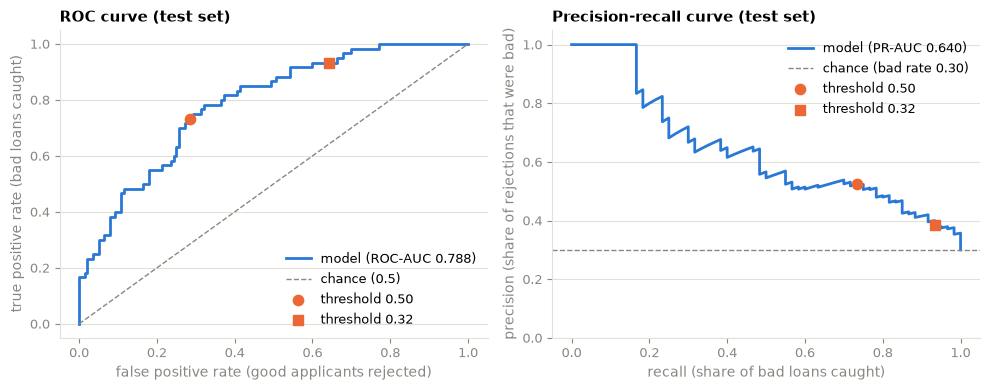

In [7]:
from sklearn.metrics import precision_recall_curve, roc_curve

y_test, proba = results["y_test"].to_numpy(), results["test_proba"]
t = metrics["threshold"]["chosen"]
m05, mt = metrics["test"]["at_default_threshold"], metrics["test"]["at_chosen_threshold"]
fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(fpr, tpr, color=GOOD, linewidth=2, label=f"model (ROC-AUC {m05['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="chance (0.5)")
for m, label, marker in [(m05, "threshold 0.50", "o"), (mt, f"threshold {t:.2f}", "s")]:
    cm = m["confusion_matrix"]
    ax.scatter(cm["fp"] / (cm["fp"] + cm["tn"]), cm["tp"] / (cm["tp"] + cm["fn"]),
               color=BAD, marker=marker, s=55, zorder=3, label=label)
tidy(ax, "ROC curve (test set)")
ax.set_xlabel("false positive rate (good applicants rejected)", color=MUTED)
ax.set_ylabel("true positive rate (bad loans caught)", color=MUTED)
ax.legend(frameon=False, fontsize=9, loc="lower right")

ax = axes[1]
ax.plot(rec, prec, color=GOOD, linewidth=2, label=f"model (PR-AUC {m05['pr_auc']:.3f})")
ax.axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"chance (bad rate {y_test.mean():.2f})")
for m, label, marker in [(m05, "threshold 0.50", "o"), (mt, f"threshold {t:.2f}", "s")]:
    ax.scatter(m["recall_bad"], m["precision_bad"], color=BAD, marker=marker, s=55, zorder=3, label=label)
tidy(ax, "Precision-recall curve (test set)")
ax.set_xlabel("recall (share of bad loans caught)", color=MUTED)
ax.set_ylabel("precision (share of rejections that were bad)", color=MUTED)
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_pr_curves.png", dpi=150)
plt.show()

### Why the threshold is not 0.5

Under the dataset's cost matrix (a missed bad loan costs 5, a wrongly rejected good applicant costs 1) the
cheapest threshold on out-of-fold training predictions is well below 0.5. The price is volume: the bank
rejects many more applicants. This is a **business decision**, and the cost ratio is an assumption.

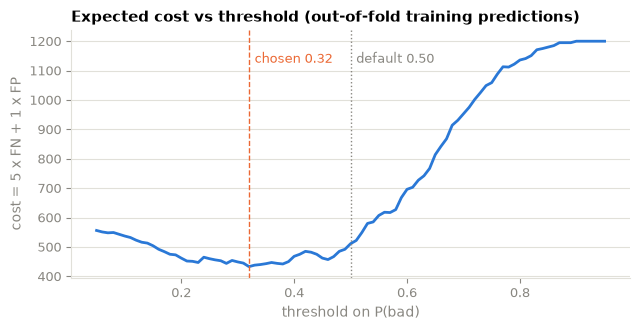

,operating point,ROC-AUC,PR-AUC,precision (bad),recall (bad),F1 (bad),accuracy,TN,FP,FN,TP,rejected,cost
0,threshold 0.50,0.788,0.64,0.524,0.733,0.611,0.72,100,40,16,44,42%,120.0
1,threshold 0.32,0.788,0.64,0.384,0.933,0.544,0.53,50,90,4,56,73%,110.0


In [8]:
ct = results["cost_table"]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(ct["threshold"], ct["cost"], color=GOOD, linewidth=2)
ax.axvline(t, color=BAD, linestyle="--", linewidth=1)
ax.text(t + 0.01, ct["cost"].max() * 0.97, f"chosen {t:.2f}", color=BAD, fontsize=9, va="top")
ax.axvline(0.5, color=MUTED, linestyle=":", linewidth=1)
ax.text(0.51, ct["cost"].max() * 0.97, "default 0.50", color=MUTED, fontsize=9, va="top")
tidy(ax, "Expected cost vs threshold (out-of-fold training predictions)")
ax.set_xlabel("threshold on P(bad)", color=MUTED)
ax.set_ylabel("cost = 5 x FN + 1 x FP", color=MUTED)
fig.tight_layout()
fig.savefig(FIG_DIR / "cost_vs_threshold.png", dpi=150)
plt.show()

rows = []
for label, m in [("threshold 0.50", m05), (f"threshold {t:.2f}", mt)]:
    cm = m["confusion_matrix"]
    rows.append({"operating point": label, "ROC-AUC": round(m["roc_auc"], 3), "PR-AUC": round(m["pr_auc"], 3),
                 "precision (bad)": round(m["precision_bad"], 3), "recall (bad)": round(m["recall_bad"], 3),
                 "F1 (bad)": round(m["f1_bad"], 3), "accuracy": round(m["accuracy"], 3),
                 "TN": cm["tn"], "FP": cm["fp"], "FN": cm["fn"], "TP": cm["tp"],
                 "rejected": f"{m['rejected_share']:.0%}", "cost": m["expected_cost"]})
pd.DataFrame(rows)

## 6. Interpretability: what the logistic regression learned

Even when a tree ensemble wins on ROC-AUC, the logistic-regression candidate is worth keeping: its
coefficients say *which way* each input pushes the odds of default. Numeric inputs are standardised, so a
coefficient is the change in log-odds per +1 standard deviation; `exp(coefficient)` is the odds ratio.
One-hot coefficients are best compared within the same original column.

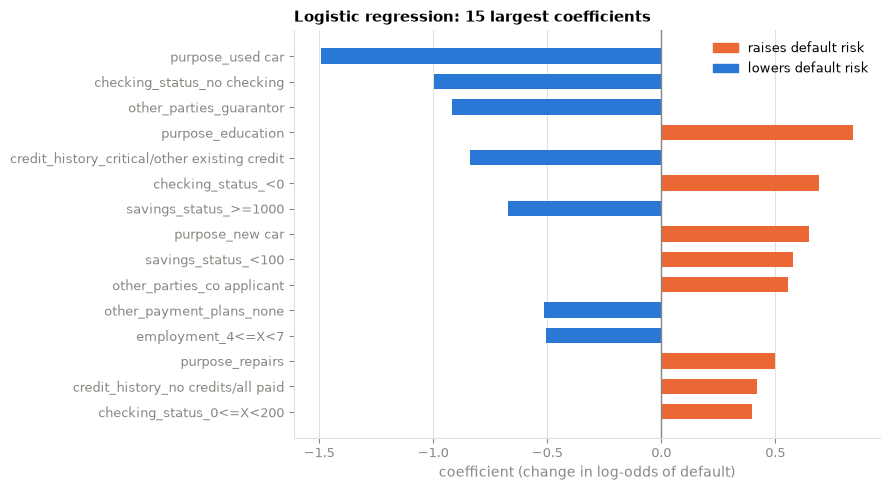

,feature,coefficient,odds_ratio
0,purpose_used car,-1.494,0.225
1,checking_status_no checking,-0.996,0.369
2,other_parties_guarantor,-0.916,0.400
3,purpose_education,0.842,2.322
4,credit_history_critical/other existing credit,-0.840,0.432
5,checking_status_<0,0.692,1.997
6,savings_status_>=1000,-0.673,0.510
7,purpose_new car,0.650,1.915
8,savings_status_<100,0.577,1.781
9,other_parties_co applicant,0.554,1.741


In [9]:
coef = results["coefficients"].head(15).iloc[::-1]
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coef["feature"], coef["coefficient"], color=[BAD if c > 0 else GOOD for c in coef["coefficient"]], height=0.6)
ax.axvline(0, color=MUTED, linewidth=1)
tidy(ax, "Logistic regression: 15 largest coefficients")
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.yaxis.grid(False)
ax.set_xlabel("coefficient (change in log-odds of default)", color=MUTED)
ax.legend(handles=[Patch(color=BAD, label="raises default risk"), Patch(color=GOOD, label="lowers default risk")],
          frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "logistic_coefficients.png", dpi=150)
plt.show()

results["coefficients"].head(10).round(3)

## 7. Takeaways

* Random Forest beat Logistic Regression in cross-validation by a small margin (about 0.01 ROC-AUC, well
  inside one standard deviation across folds), so the choice is not strongly supported by 800 rows.
  Logistic regression remains the interpretable baseline.
* The cost-based threshold (0.32) catches far more bad loans than 0.50 (recall 0.93 vs 0.73 on the test set)
  and lowers the expected cost (110 vs 120), but rejects 73% of applicants instead of 42%. Whether that
  trade is acceptable is a business question, not a modelling one.
* Dropping `age`, `personal_status` and `foreign_worker` costs about 0.003 cross-validated ROC-AUC: the
  fairness decision is almost free here.
* Every number above is reproduced by `python src/train.py` and stored in `reports/metrics.json`.